# BTC/USDT 小时频 DQN 网格门控 — 初步技术验证

**目标**：用 DQN 替换 `DynamicBandMAGatedGridStrategy` 中的 MA 门控（`close < MA(1440)`），让智能体每小时决定「正常挂单(0)」还是「撤单观望(1)」。网格动态上下界、动态层数、事件驱动重锚定、底仓保留等机制全部沿用 `notebook/dynamic_grid_backtest_eth_dynamic_band.ipynb` 的逻辑。动态带采用**日频等价映射**：在日频上计算 `mid=MA(60)`、`half=4×ATR(14)` 与层数，再 `shift(1)+ffill` 映射到小时频，避免直接用小时 ATR 导致半宽被低估约 5.4 倍的问题。

**动作**：`0=正常挂单(GRID)`，`1=撤单观望(SUSPENDED)`。

**奖励**：RL 门控组合相对「永不撤单动态带基准」的每小时超额收益，放大 100 倍并 clip 到 [-1,1]，外加切换惩罚。

**训练/测试**：2022-01-01 ~ 2025-12-31 训练，2026-01-01 ~ 2026-09-30 测试。

In [1]:
from pathlib import Path
import sys
import warnings

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scripts.dqn_gate_env as g
from stable_baselines3 import DQN
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.vec_env import DummyVecEnv, VecFrameStack

%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
warnings.filterwarnings("ignore")

print("项目根目录:", PROJECT_ROOT)
print("特征数量:", len(g.FEATURE_COLS))

项目根目录: /home/nullwinters/Projects/CryptoGrid
特征数量: 22


In [2]:
# ================= 统一可调参数 =================

# --- 数据与区间 ---
DATA_PATH = PROJECT_ROOT / "data" / "btc_usdt_1h.csv"
START_TRAIN = "2022-01-01"
END_TRAIN   = "2025-12-31 23:00:00"
START_TEST  = "2026-01-01"
END_TEST    = "2026-09-30 23:00:00"

# --- 动态带网格（日频等价映射到小时频：方案 A） ---
BAND_MODE = "daily"       # daily=日频计算后 shift(1)+ffill 映射；hourly=直接在小时频计算（旧口径）
MA_WINDOW = 60            # 日频 mid=MA(60)
ATR_WINDOW = 14           # 日频 half=K×ATR(14)
FEATURE_MA_WINDOW = 1440  # 特征中均线类指标的小时频窗口
K_WIDTH = 4.0
TARGET_RET = 0.015
MIN_STEPS, MAX_STEPS = 5, 200
REANCHOR_MIN_GAP = 168    # 7 日
REANCHOR_DEV = 0.25

# --- 资金 / 费率 / 每格数量 ---
INIT_CAPITAL = 100_000
FEE_RATE = 0.001
INITIAL_BASE_RATIO = 0.5
VOLUME_PER_GRID = 0.01    # BTC 数量（约 0.5%~1% 资金/格）
PRICE_TICK = 0.01

# --- DQN ---
SEED = 42
TOTAL_TIMESTEPS = 150_000
GAMMA = 0.99
LEARNING_RATE = 1e-4
BUFFER_SIZE = 100_000
BATCH_SIZE = 128
TRAIN_FREQ = 4
TARGET_UPDATE_INTERVAL = 2000
EXPLORATION_FRACTION = 0.1
EXPLORATION_FINAL_EPS = 0.02
N_STACK = 4
SWITCH_PENALTY = 0.05       # 抖单惩罚（奖励中扣除）
MODEL_PATH = PROJECT_ROOT / "data" / "dqn_gate_model.zip"
ACTION_CSV = PROJECT_ROOT / "data" / "dqn_gate_test_actions.csv"
RETRAIN = True              # False 时若模型存在则直接加载

In [3]:
# ================= 数据校验（duckdb）与加载 =================
con = duckdb.connect()
q = f"""
SELECT min(timestamp) AS t0,
       max(timestamp) AS t1,
       count(*) AS n,
       count(*) FILTER (WHERE timestamp >= '{START_TRAIN}' AND timestamp <= '{END_TRAIN}') AS train_n,
       count(*) FILTER (WHERE timestamp >= '{START_TEST}' AND timestamp <= '{END_TEST}') AS test_n
FROM read_csv_auto('{DATA_PATH}')
"""
df_check = con.execute(q).fetchdf()
df_check

,t0,t1,n,train_n,test_n
0,2021-01-01,2026-10-11 23:00:00,50626,35063,6552


In [4]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
print(f"行数: {len(df)}")
print(f"时间范围: {df['timestamp'].min()} ~ {df['timestamp'].max()}")
print(f"缺失值总数: {int(df.isna().sum().sum())}")
print(f"训练集小时数: {int(((df['timestamp'] >= START_TRAIN) & (df['timestamp'] <= END_TRAIN)).sum())}")
print(f"测试集小时数: {int(((df['timestamp'] >= START_TEST) & (df['timestamp'] <= END_TEST)).sum())}")
df.head(3)

行数: 50626
时间范围: 2021-01-01 00:00:00 ~ 2026-10-11 23:00:00
缺失值总数: 0
训练集小时数: 35063
测试集小时数: 6552


,timestamp,open,high,low,close,volume
0,2021-01-01 00:00:00,28923.63,29031.34,28690.17,28995.13,2311.811445
1,2021-01-01 01:00:00,28995.13,29470.00,28960.35,29409.99,5403.068471
2,2021-01-01 02:00:00,29410.00,29465.26,29120.03,29194.65,2384.231560


In [5]:
# ================= 特征与动态 bounds =================
features, bounds = g.prepare_data(
    df, ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
    target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS, pricetick=PRICE_TICK,
    feature_ma_window=FEATURE_MA_WINDOW, band_mode=BAND_MODE,
)

# 训练集特征统计，用于归一化（测试集复用同一组统计，避免泄漏）
feature_mean, feature_std = g.get_feature_stats(
    df, START_TRAIN, END_TRAIN, ma_window=MA_WINDOW, atr_window=ATR_WINDOW,
    k_width=K_WIDTH, target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS, pricetick=PRICE_TICK,
    feature_ma_window=FEATURE_MA_WINDOW, band_mode=BAND_MODE,
)

print("特征矩阵:", features[g.FEATURE_COLS].shape)
train_mask = (df["timestamp"] >= START_TRAIN) & (df["timestamp"] <= END_TRAIN)
test_mask = (df["timestamp"] >= START_TEST) & (df["timestamp"] <= END_TEST)
print("训练集特征 NaN 数:", int(features[g.FEATURE_COLS][train_mask].isna().sum().sum()))
for name, m in [("训练集", train_mask), ("测试集", test_mask)]:
    cov = ((df.loc[m, "close"].to_numpy() >= bounds.loc[m, "lower"].to_numpy()) &
           (df.loc[m, "close"].to_numpy() <= bounds.loc[m, "upper"].to_numpy())).mean()
    print(f"{name}动态带覆盖比例: {cov*100:.1f}% | half 中位数: {bounds.loc[m, 'half'].median():.0f} | steps 中位数: {bounds.loc[m, 'steps'].median():.0f}")
print("训练集 close < mid(日频等价) 占比: %.1f%%" % (
    100 * (df.loc[train_mask, "close"].to_numpy() < bounds.loc[train_mask, "mid"].to_numpy()).mean()
))
display(features[g.FEATURE_COLS].head())


特征矩阵: (50626, 22)
训练集特征 NaN 数: 0
训练集动态带覆盖比例: 80.8% | half 中位数: 7942 | steps 中位数: 21
测试集动态带覆盖比例: 74.4% | half 中位数: 9261 | steps 中位数: 17
训练集 close < mid(日频等价) 占比: 48.9%


,ret1,ret6,ret24,ret168,price_vs_mid,price_atr_pos,ma_dist168,ma_dist720,ma_dist1440,slope20,...,er168,adx14,di_ratio,vol24,vol168,vol_ratio,atr_pct,range_pos60,vol_intensity24,vol_zscore168
0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.014308,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.007322,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.002869,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.001984,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
# ================= 环境自检 =================
def make_train_env():
    return g.GridGateEnv(
        df, START_TRAIN, END_TRAIN,
        feature_mean=feature_mean, feature_std=feature_std,
        ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
        target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
        reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
        volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
        initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK,
        feature_ma_window=FEATURE_MA_WINDOW, band_mode=BAND_MODE,
        switch_penalty=SWITCH_PENALTY,
    )

env = make_train_env()
check_env(env, warn=True)
obs, _ = env.reset()
print("observation_space:", env.observation_space)
print("action_space:", env.action_space)
print("obs shape:", obs.shape)

# 随机动作走 5 步，确认状态机与奖励 shape 正常
for a in [0, 0, 1, 0, 1]:
    obs, r, done, trunc, info = env.step(a)
    print(f"a={a} reward={r:.4f} done={done} state={info['state']} nav={info['nav_rl']:,.0f} bench={info['nav_bench']:,.0f}")

observation_space: Box(-inf, inf, (23,), float32)
action_space: Discrete(2)
obs shape: (23,)
a=0 reward=0.0000 done=False state=GRID nav=100,081 bench=100,081
a=0 reward=0.0000 done=False state=GRID nav=100,117 bench=100,117
a=1 reward=-0.0500 done=False state=SUSPENDED nav=100,118 bench=100,118
a=0 reward=-0.0500 done=False state=GRID nav=100,009 bench=100,009
a=1 reward=-0.0496 done=False state=SUSPENDED nav=100,525 bench=100,524


In [7]:
# ================= 基准回测（训练集 & 测试集） =================
def fmt_stats(st):
    if not st:
        return "n/a"
    return (f"收益 {st['total_return']*100:.2f}% | 年化 {st['annual_return']*100:.2f}% | "
            f"回撤 {st['max_dd']*100:.2f}% | Sharpe {st['sharpe']:.3f} | Calmar {st['calmar']:.3f}")

bench_rows = []
for split, start, end in [("训练集", START_TRAIN, END_TRAIN), ("测试集", START_TEST, END_TEST)]:
    for name, mode in [("永不撤单动态带", "no_gate"), ("MA门控动态带", "ma_gate")]:
        res = g.simulate(
            df, start, end, mode=mode,
            ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
            target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
            reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
            volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
            initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK,
            band_mode=BAND_MODE,
        )
        bench_rows.append({
            "数据集": split, "策略": name,
            "总收益率%": round(res["stats"]["total_return"]*100, 2),
            "年化收益%": round(res["stats"]["annual_return"]*100, 2),
            "最大回撤%": round(res["stats"]["max_dd"]*100, 2),
            "Sharpe": round(res["stats"]["sharpe"], 3),
            "Calmar": round(res["stats"]["calmar"], 3),
            "期末NAV": round(res["stats"]["end_nav"], 0),
            "成交笔数": res["n_trades"],
            "重锚定": res["reanchor_count"],
            "切换次数": res["switch_count"],
        })
bench_df = pd.DataFrame(bench_rows)
display(bench_df)

,数据集,策略,总收益率%,年化收益%,最大回撤%,Sharpe,Calmar,期末NAV,成交笔数,重锚定,切换次数
0,训练集,永不撤单动态带,24.73,5.68,-34.66,0.373,0.164,124665.0,14875,70,0
1,训练集,MA门控动态带,36.21,8.03,-35.58,0.456,0.226,136138.0,6490,194,284
2,测试集,永不撤单动态带,-3.09,-4.10,-21.96,-0.106,-0.187,96866.0,2072,18,0
3,测试集,MA门控动态带,-3.90,-5.19,-21.00,-0.193,-0.247,96047.0,829,58,93


In [8]:
# ================= DQN 训练 =================
def make_env_for_sb3():
    return make_train_env()

if RETRAIN or not MODEL_PATH.exists():
    print(f"开始训练 DQN：{TOTAL_TIMESTEPS} 步 ...")
    vec_env = DummyVecEnv([make_env_for_sb3])
    vec_env = VecFrameStack(vec_env, n_stack=N_STACK)
    model = DQN(
        "MlpPolicy", vec_env,
        learning_rate=LEARNING_RATE,
        buffer_size=BUFFER_SIZE,
        batch_size=BATCH_SIZE,
        gamma=GAMMA,
        train_freq=TRAIN_FREQ,
        target_update_interval=TARGET_UPDATE_INTERVAL,
        exploration_fraction=EXPLORATION_FRACTION,
        exploration_final_eps=EXPLORATION_FINAL_EPS,
        seed=SEED,
        verbose=1,
    )
    model.learn(total_timesteps=TOTAL_TIMESTEPS, log_interval=2000)
    model.save(MODEL_PATH)
    print("模型已保存:", MODEL_PATH)
else:
    model = DQN.load(MODEL_PATH)
    print("已加载既有模型:", MODEL_PATH)

开始训练 DQN：150000 步 ...


Using cuda device


模型已保存: /home/nullwinters/Projects/CryptoGrid/data/dqn_gate_model.zip


In [9]:
# ================= 测试集：greedy 策略生成动作 =================
def make_test_env():
    return g.GridGateEnv(
        df, START_TEST, END_TEST,
        feature_mean=feature_mean, feature_std=feature_std,
        ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
        target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
        reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
        volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
        initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK,
        feature_ma_window=FEATURE_MA_WINDOW, band_mode=BAND_MODE,
        switch_penalty=SWITCH_PENALTY,
    )

eval_env = DummyVecEnv([make_test_env])
eval_env = VecFrameStack(eval_env, n_stack=N_STACK)
obs = eval_env.reset()

n_test = int(((df["timestamp"] >= START_TEST) & (df["timestamp"] <= END_TEST)).sum())
actions = []
for _ in range(n_test):
    a_arr, _ = model.predict(obs, deterministic=True)
    a = int(a_arr[0])
    actions.append(a)
    obs, r, done, info = eval_env.step([a])

action_s = pd.Series(actions)
print(f"测试集决策次数: {len(actions)}")
print(f"动作分布: 0(正常) {action_s.eq(0).mean()*100:.1f}% | 1(观望) {action_s.eq(1).mean()*100:.1f}%")
print(f"切换次数: {int((action_s.diff().fillna(0) != 0).sum())}")

# 保存动作序列，便于后续 vnpy 回测复现
pd.Series(actions, name="action").to_csv(ACTION_CSV, index=False)
print("动作序列已保存:", ACTION_CSV)

测试集决策次数: 6552
动作分布: 0(正常) 40.7% | 1(观望) 59.3%
切换次数: 398
动作序列已保存: /home/nullwinters/Projects/CryptoGrid/data/dqn_gate_test_actions.csv


In [10]:
# ================= 测试集：RL 门控回测 + 对比 =================
rl_res = g.simulate(
    df, START_TEST, END_TEST, actions=actions,
    ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
    target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
    reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
    volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
    initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK,
    band_mode=BAND_MODE,
)
no_gate_res = g.simulate(df, START_TEST, END_TEST, mode="no_gate",
                         ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
                         target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
                         reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
                         volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
                         initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK, band_mode=BAND_MODE)
ma_gate_res = g.simulate(df, START_TEST, END_TEST, mode="ma_gate",
                         ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
                         target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS,
                         reanchor_min_gap=REANCHOR_MIN_GAP, reanchor_dev=REANCHOR_DEV,
                         volume_per_grid=VOLUME_PER_GRID, fee_rate=FEE_RATE,
                         initial_base_ratio=INITIAL_BASE_RATIO, pricetick=PRICE_TICK, band_mode=BAND_MODE)

cmp_rows = []
for name, res in [("RL门控(DQN)", rl_res), ("永不撤单动态带", no_gate_res), ("MA门控动态带", ma_gate_res)]:
    st = res["stats"]; bh = res["bh_stats"]
    cmp_rows.append({
        "策略": name,
        "总收益率%": round(st["total_return"]*100, 2),
        "年化收益%": round(st["annual_return"]*100, 2),
        "最大回撤%": round(st["max_dd"]*100, 2),
        "Sharpe": round(st["sharpe"], 3),
        "Calmar": round(st["calmar"], 3),
        "期末NAV": round(st["end_nav"], 0),
        "成交笔数": res["n_trades"],
        "重锚定": res["reanchor_count"],
        "切换次数": res["switch_count"],
    })
cmp_rows.append({
    "策略": "Buy&Hold",
    "总收益率%": round(no_gate_res["bh_stats"]["total_return"]*100, 2),
    "年化收益%": round(no_gate_res["bh_stats"]["annual_return"]*100, 2),
    "最大回撤%": round(no_gate_res["bh_stats"]["max_dd"]*100, 2),
    "Sharpe": round(no_gate_res["bh_stats"]["sharpe"], 3),
    "Calmar": round(no_gate_res["bh_stats"]["calmar"], 3),
    "期末NAV": round(no_gate_res["bh_stats"]["end_nav"], 0),
    "成交笔数": 1, "重锚定": 0, "切换次数": 0,
})
cmp_df = pd.DataFrame(cmp_rows)
display(cmp_df)

,策略,总收益率%,年化收益%,最大回撤%,Sharpe,Calmar,期末NAV,成交笔数,重锚定,切换次数
0,RL门控(DQN),-7.27,-9.59,-17.93,-0.679,-0.535,92688.0,625,200,398
1,永不撤单动态带,-3.09,-4.10,-21.96,-0.106,-0.187,96866.0,2072,18,0
2,MA门控动态带,-3.90,-5.19,-21.00,-0.193,-0.247,96047.0,829,58,93
3,Buy&Hold,-4.77,-6.32,-40.31,0.064,-0.157,95233.0,1,0,0


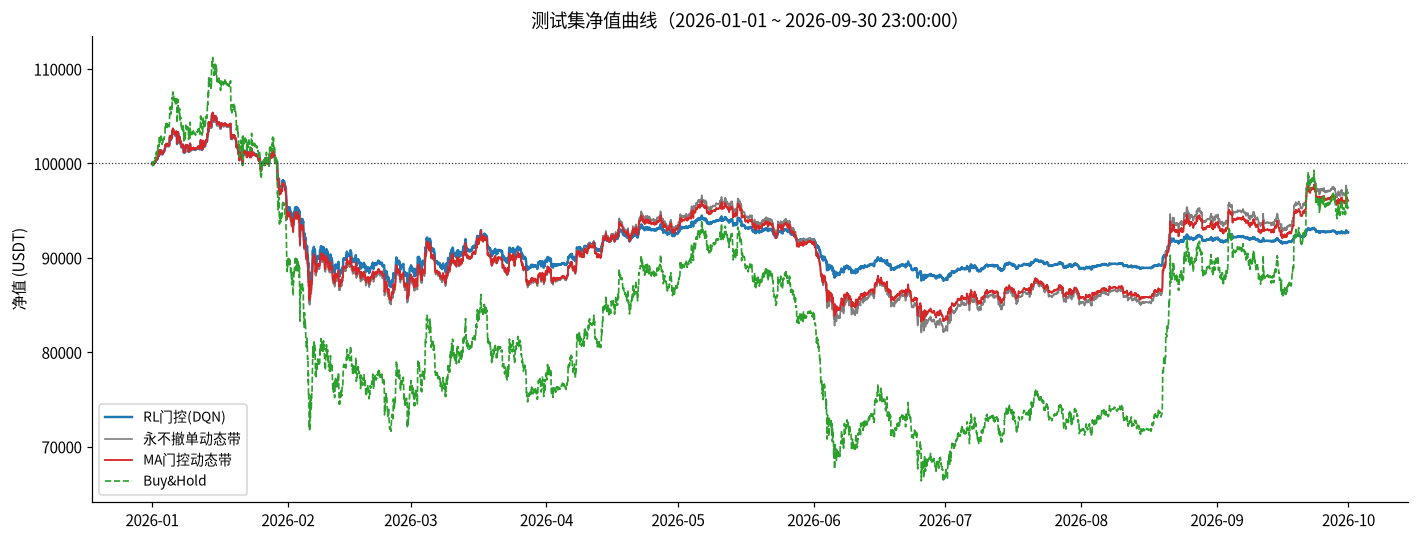

In [11]:
# ================= 图 1：测试集净值曲线 =================
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(rl_res["timestamps"], rl_res["nav"].values, lw=1.6, color="#1f77b4", label="RL门控(DQN)")
ax.plot(no_gate_res["timestamps"], no_gate_res["nav"].values, lw=1.1, color="#7f7f7f", label="永不撤单动态带")
ax.plot(ma_gate_res["timestamps"], ma_gate_res["nav"].values, lw=1.2, color="#d62728", label="MA门控动态带")
ax.plot(no_gate_res["timestamps"], no_gate_res["buyhold_nav"].values, lw=1.1, color="#2ca02c", ls="--", label="Buy&Hold")
ax.axhline(INIT_CAPITAL, color="#333", ls=":", lw=0.8)
ax.set_title(f"测试集净值曲线（{START_TEST} ~ {END_TEST}）")
ax.set_ylabel("净值 (USDT)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

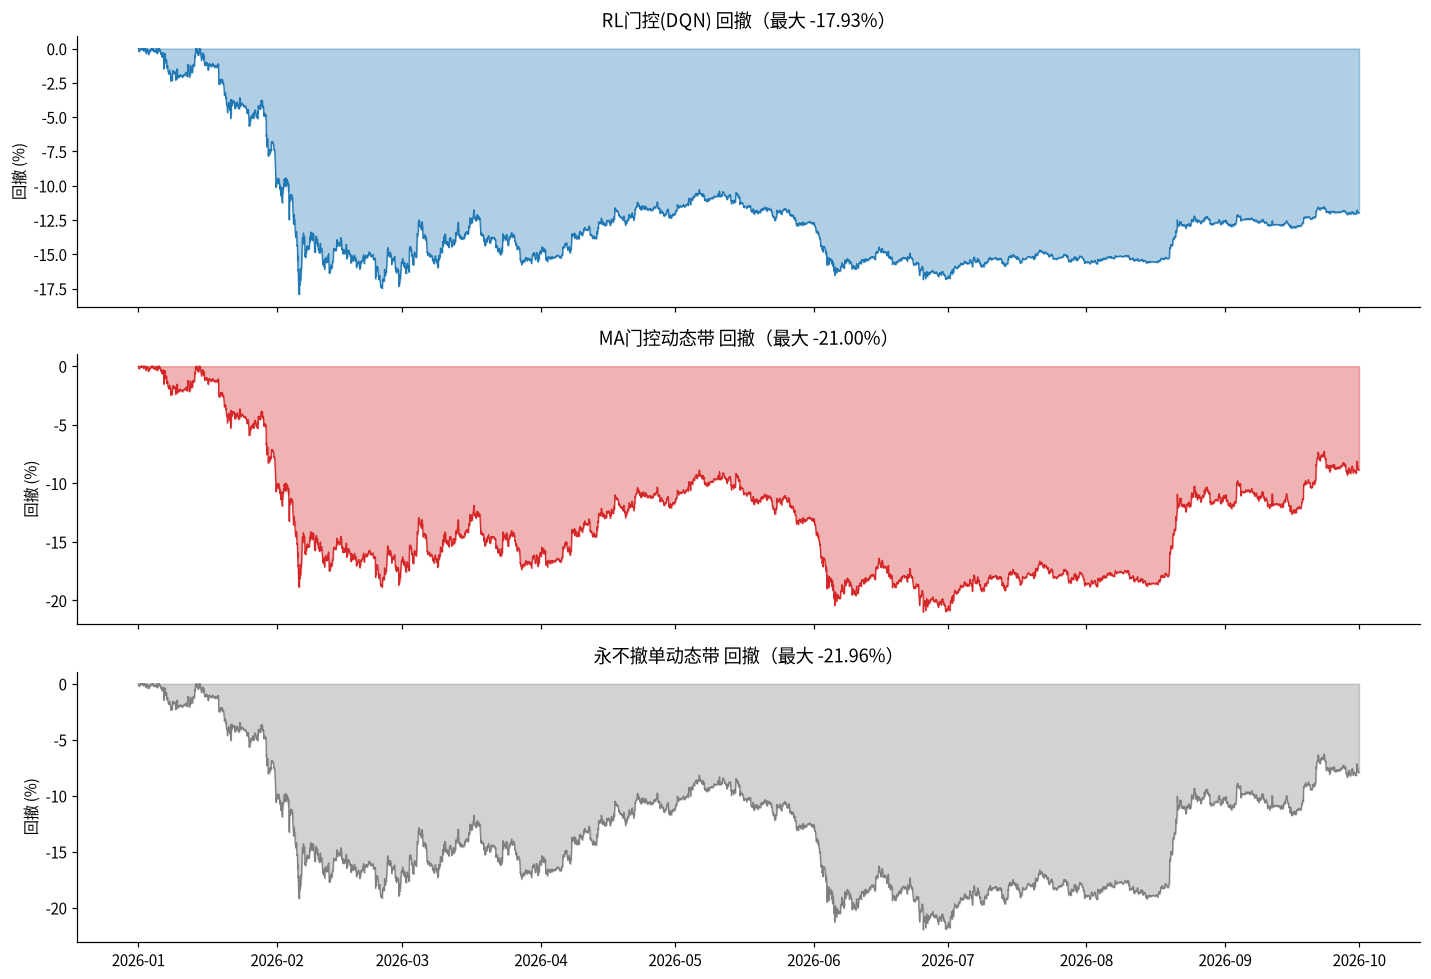

In [12]:
# ================= 图 2：测试集回撤 =================
def drawdown(nav):
    return nav / nav.cummax() - 1

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (name, res, color) in zip(axes, [
    ("RL门控(DQN)", rl_res, "#1f77b4"),
    ("MA门控动态带", ma_gate_res, "#d62728"),
    ("永不撤单动态带", no_gate_res, "#7f7f7f"),
]):
    dd = drawdown(res["nav"])
    ax.fill_between(res["timestamps"], dd*100, 0, color=color, alpha=0.35)
    ax.plot(res["timestamps"], dd*100, lw=0.8, color=color)
    ax.set_title(f"{name} 回撤（最大 {dd.min()*100:.2f}%）")
    ax.set_ylabel("回撤 (%)")
plt.tight_layout()
plt.show()

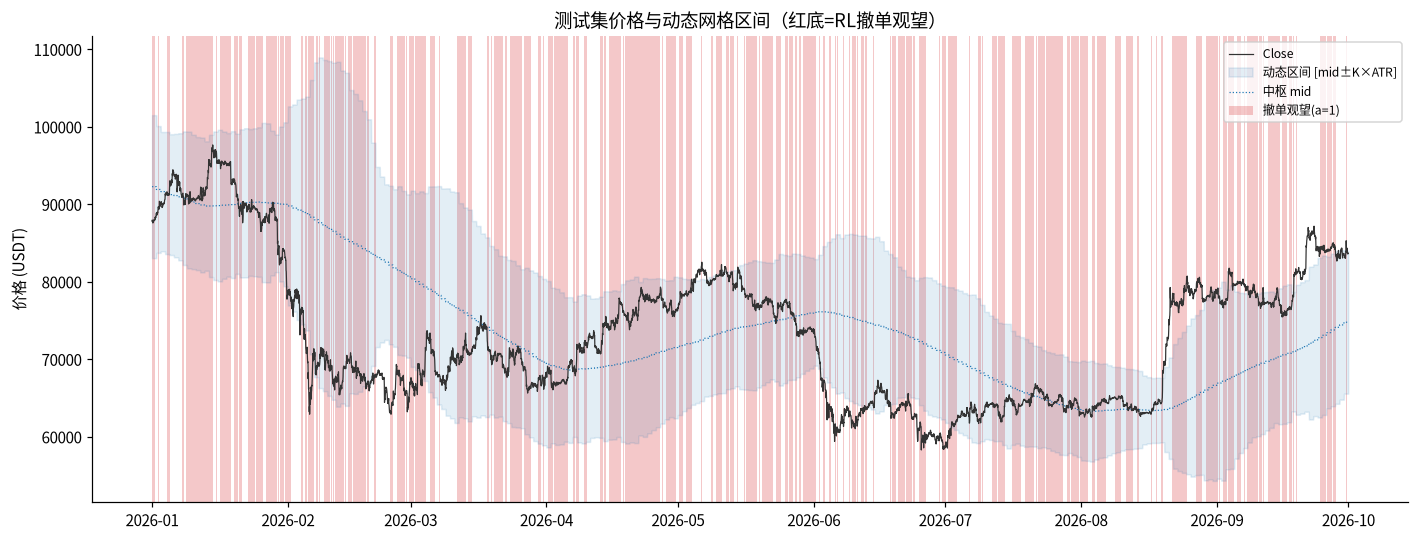

In [13]:
# ================= 图 3：价格、动态带与 RL 动作 =================
# 测试集的动态带（理论值，仅用历史数据）
_, test_bounds = g.prepare_data(
    df, ma_window=MA_WINDOW, atr_window=ATR_WINDOW, k_width=K_WIDTH,
    target_ret=TARGET_RET, min_steps=MIN_STEPS, max_steps=MAX_STEPS, pricetick=PRICE_TICK,
    feature_ma_window=FEATURE_MA_WINDOW, band_mode=BAND_MODE,
)
test_mask = (df["timestamp"] >= START_TEST) & (df["timestamp"] <= END_TEST)
t_df = df.loc[test_mask].reset_index(drop=True)
t_b = test_bounds.loc[test_mask].reset_index(drop=True)
t_actions = actions[: len(t_df)]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t_df["timestamp"], t_df["close"], lw=0.8, color="#333", label="Close", zorder=3)
ax.fill_between(t_df["timestamp"], t_b["lower"], t_b["upper"], color="#1f77b4", alpha=0.12,
                label="动态区间 [mid±K×ATR]", zorder=2)
ax.plot(t_df["timestamp"], t_b["mid"], lw=0.8, color="#1f77b4", ls=":", label="中枢 mid")
ax.fill_between(t_df["timestamp"], 0, 1,
                where=(np.array(t_actions) == 1),
                transform=ax.get_xaxis_transform(), color="#d62728", alpha=0.25, linewidth=0,
                label="撤单观望(a=1)")
ax.set_title("测试集价格与动态网格区间（红底=RL撤单观望）")
ax.set_ylabel("价格 (USDT)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

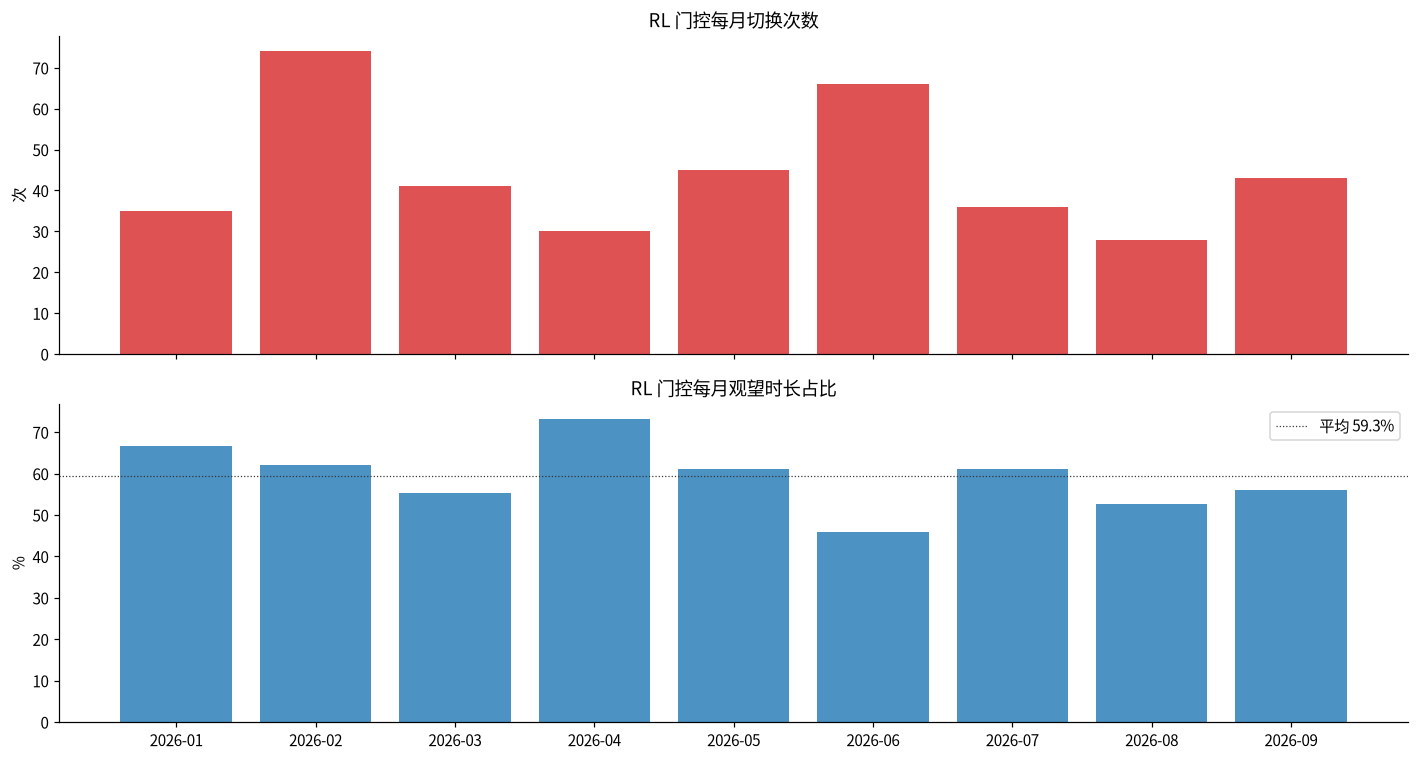

In [14]:
# ================= 图 4：月度动作切换与持仓状态 =================
t_ts = t_df["timestamp"]
monthly = pd.DataFrame({"ts": t_ts, "action": t_actions})
monthly["month"] = monthly["ts"].dt.to_period("M")
sw = monthly.groupby("month")["action"].apply(lambda x: int((x.diff().fillna(0) != 0).sum()))
susp = monthly.groupby("month")["action"].apply(lambda x: float((x == 1).mean() * 100))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].bar(sw.index.astype(str), sw.values, color="#d62728", alpha=0.8)
axes[0].set_title("RL 门控每月切换次数")
axes[0].set_ylabel("次")
axes[1].bar(susp.index.astype(str), susp.values, color="#1f77b4", alpha=0.8)
axes[1].axhline(susp.mean(), color="#333", ls=":", lw=0.8, label=f"平均 {susp.mean():.1f}%")
axes[1].set_title("RL 门控每月观望时长占比")
axes[1].set_ylabel("%")
axes[1].legend()
plt.tight_layout()
plt.show()

## 初步结论与下一步

**动态带修正（方案 A：日频等价映射）**：

1. 修正后动态带覆盖比例：训练集 80.8%、测试集 74.4%；`half` 中位数从小时频口径的 1,311 / 1,701 USDT 提升到 7,942 / 9,261 USDT，训练集约 6.1 倍；`steps` 中位数从 5（被下限截死）提升到 21 / 17。原来的「小时 ATR 半宽」显著低估了通道宽度。
2. 基准策略：训练集永不撤单动态带总收益 +24.73%、最大回撤 -34.66%，MA 门控 +36.21%/-35.58%；测试集永不撤单 -3.09%/-21.96%，MA 门控 -3.90%/-21.00%，成交 2,072 / 829 笔。

**DQN 门控（测试集 2026-01-01 ~ 2026-09-30，本 notebook 配置：150k 步、无账户状态、每格 0.01 BTC）**：

1. RL 门控总收益 -7.27%，最大回撤 -17.93%，期末 NAV 92,688；回撤小于两个网格基准（-21.96%、-21.00%）和 Buy&Hold（-40.31%），但收益低于三者。
2. 风险调整后：RL 的 Sharpe -0.679、Calmar -0.535 均差于永不撤单（-0.106 / -0.187）与 MA 门控（-0.193 / -0.247）。本窗口里门控压住回撤的代价是让出过多收益。
3. RL 动作分布为 40.7% 正常 / 59.3% 观望，切换 398 次、成交 625 笔、重锚定 200 次；与 MA 门控动作一致率 47.9%（MA 观望占比 52.5%），说明它学的是与 MA 规则不同的开关节奏。
4. 分月看差距很小：RL 在下跌月略优（1 月 -4.75% vs -5.28% / -5.29%，2 月 -7.53% vs -7.56% / -7.63%，5 月与 6 月类似），在上涨月略保守（8 月 11.68% vs 11.78% / 11.45%，9 月 2.82% vs 3.16% / 3.16%）。但连续九个月运行下累计收益落后 MA 门控约 3.4pp，差异来自路径与复利效应，而非某个月的单点表现。

**下一步**：加大训练步数、尝试 Double/Dueling DQN 与 PER；对 `switch_penalty`、`VOLUME_PER_GRID`、`TARGET_RET` 做敏感性分析；并做多种子与 walk-forward 多段验证（账户状态与奖励消融见 `scripts/account_state_ablation.py`、`scripts/reward_ablation.py`）。vnpy 一致性验证已完成，见下一节。


## vnpy 一致性验证

将 `data/dqn_gate_test_actions.csv` 中的 DQN 门控动作序列注入 vnpy 小时频动态带策略，验证 Gym 撮合模拟器与 vnpy 回测引擎的一致性。

**实现方式**：`vnpy.alpha.AlphaLab` 仅支持 DAILY / MINUTE 两种 bar 频率，因此把小时 bar 以 `Interval.MINUTE` 存入独立实验室 `data/vnpy_lab_btc_1h`，引擎按小时时间戳逐根回放。动态带 bounds 与 Gym 同口径（`build_bounds(band_mode="daily")`）。vnpy 策略与 Gym 的唯一有意差异：vnpy 底仓订单在下一根 bar 成交（Gym 在首根 bar 收盘立即成交），因此成交笔数多 1 笔（底仓）。

**验证结果（2026-01-01 ~ 2026-09-30）**：三个策略的 vnpy 与 Gym 期末 NAV 逐一相同（92,688 / 96,047 / 96,866），成交笔数偏差恒为 +1（vnpy 底仓在次根 bar 成交），总收益偏差 0.04~0.05pp，最大回撤偏差 0.30~0.48pp，一致性判定通过。


In [15]:
import subprocess, json, sys

script = PROJECT_ROOT / "scripts" / "vnpy_hourly_grid_backtest.py"
result = subprocess.run(
    [sys.executable, str(script), "--mode", "all", "--print-json"],
    capture_output=True, text=True, cwd=PROJECT_ROOT,
)
if result.returncode != 0:
    print("STDOUT:", result.stdout)
    print("STDERR:", result.stderr)
    raise RuntimeError("vnpy 回测脚本执行失败")

stdout_lines = [ln for ln in result.stdout.strip().splitlines() if ln.strip()]
cmp_json = json.loads(stdout_lines[-1])
cmp_df = pd.DataFrame(cmp_json)
display(cmp_df)

# 计算 vnpy 与 Gym 的指标偏差
diff_rows = []
for strat in cmp_df["策略"].unique():
    sub = cmp_df[cmp_df["策略"] == strat].set_index("回测")
    diff_rows.append({
        "策略": strat,
        "总收益率偏差(pp)": round(sub.loc["vnpy", "总收益率%"] - sub.loc["Gym", "总收益率%"], 2),
        "最大回撤偏差(pp)": round(sub.loc["vnpy", "最大回撤%"] - sub.loc["Gym", "最大回撤%"], 2),
        "期末NAV偏差": round(sub.loc["vnpy", "期末NAV"] - sub.loc["Gym", "期末NAV"], 0),
        "成交笔数偏差": int(sub.loc["vnpy", "成交笔数"] - sub.loc["Gym", "成交笔数"]),
    })
diff_df = pd.DataFrame(diff_rows)
print("vnpy - Gym 指标偏差（成交笔数偏差 +1 为 vnpy 包含底仓成交）")
display(diff_df)

# 一致性判定
pass_all = all(abs(diff_df["总收益率偏差(pp)"]) < 2.0)
print("一致性判定:", "通过（|总收益率偏差| < 2pp，且成交笔数偏差仅为底仓 +1）" if pass_all else "未通过")

,策略,回测,总收益率%,最大回撤%,期末NAV,成交笔数,重锚定
0,RL门控(DQN),vnpy,-7.31,-17.63,92688.0,626,200
1,RL门控(DQN),Gym,-7.27,-17.93,92688.0,625,200
2,MA门控动态带,vnpy,-3.95,-20.55,96047.0,830,58
3,MA门控动态带,Gym,-3.90,-21.00,96047.0,829,58
4,永不撤单动态带,vnpy,-3.13,-21.48,96866.0,2073,18
5,永不撤单动态带,Gym,-3.09,-21.96,96866.0,2072,18


vnpy - Gym 指标偏差（成交笔数偏差 +1 为 vnpy 包含底仓成交）


,策略,总收益率偏差(pp),最大回撤偏差(pp),期末NAV偏差,成交笔数偏差
0,RL门控(DQN),-0.04,0.30,0.0,1
1,MA门控动态带,-0.05,0.45,0.0,1
2,永不撤单动态带,-0.04,0.48,0.0,1


一致性判定: 通过（|总收益率偏差| < 2pp，且成交笔数偏差仅为底仓 +1）
